# Module 11.1 — GloVe: Global Vectors for Word Representation 🧠

Bro, since you've completed Word2Vec, let's build directly on that knowledge. The key idea behind GloVe is to learn word embeddings from global word–context co-occurrence statistics.

## 1. Why do we need GloVe?

You already know that Word2Vec learns dense word vectors by predicting target words from context, or context words from a target word.

GloVe approaches the problem from a different angle: instead of focusing primarily on individual prediction examples, it learns from how frequently words co-occur throughout the corpus.

For example, consider these sentences:

- “The cat drinks milk.”
- “The dog drinks milk.”
- “The cat chases the mouse.”
- “The dog chases the ball.”

The words cat and dog appear in similar contexts. That pattern provides evidence that they have related meanings.

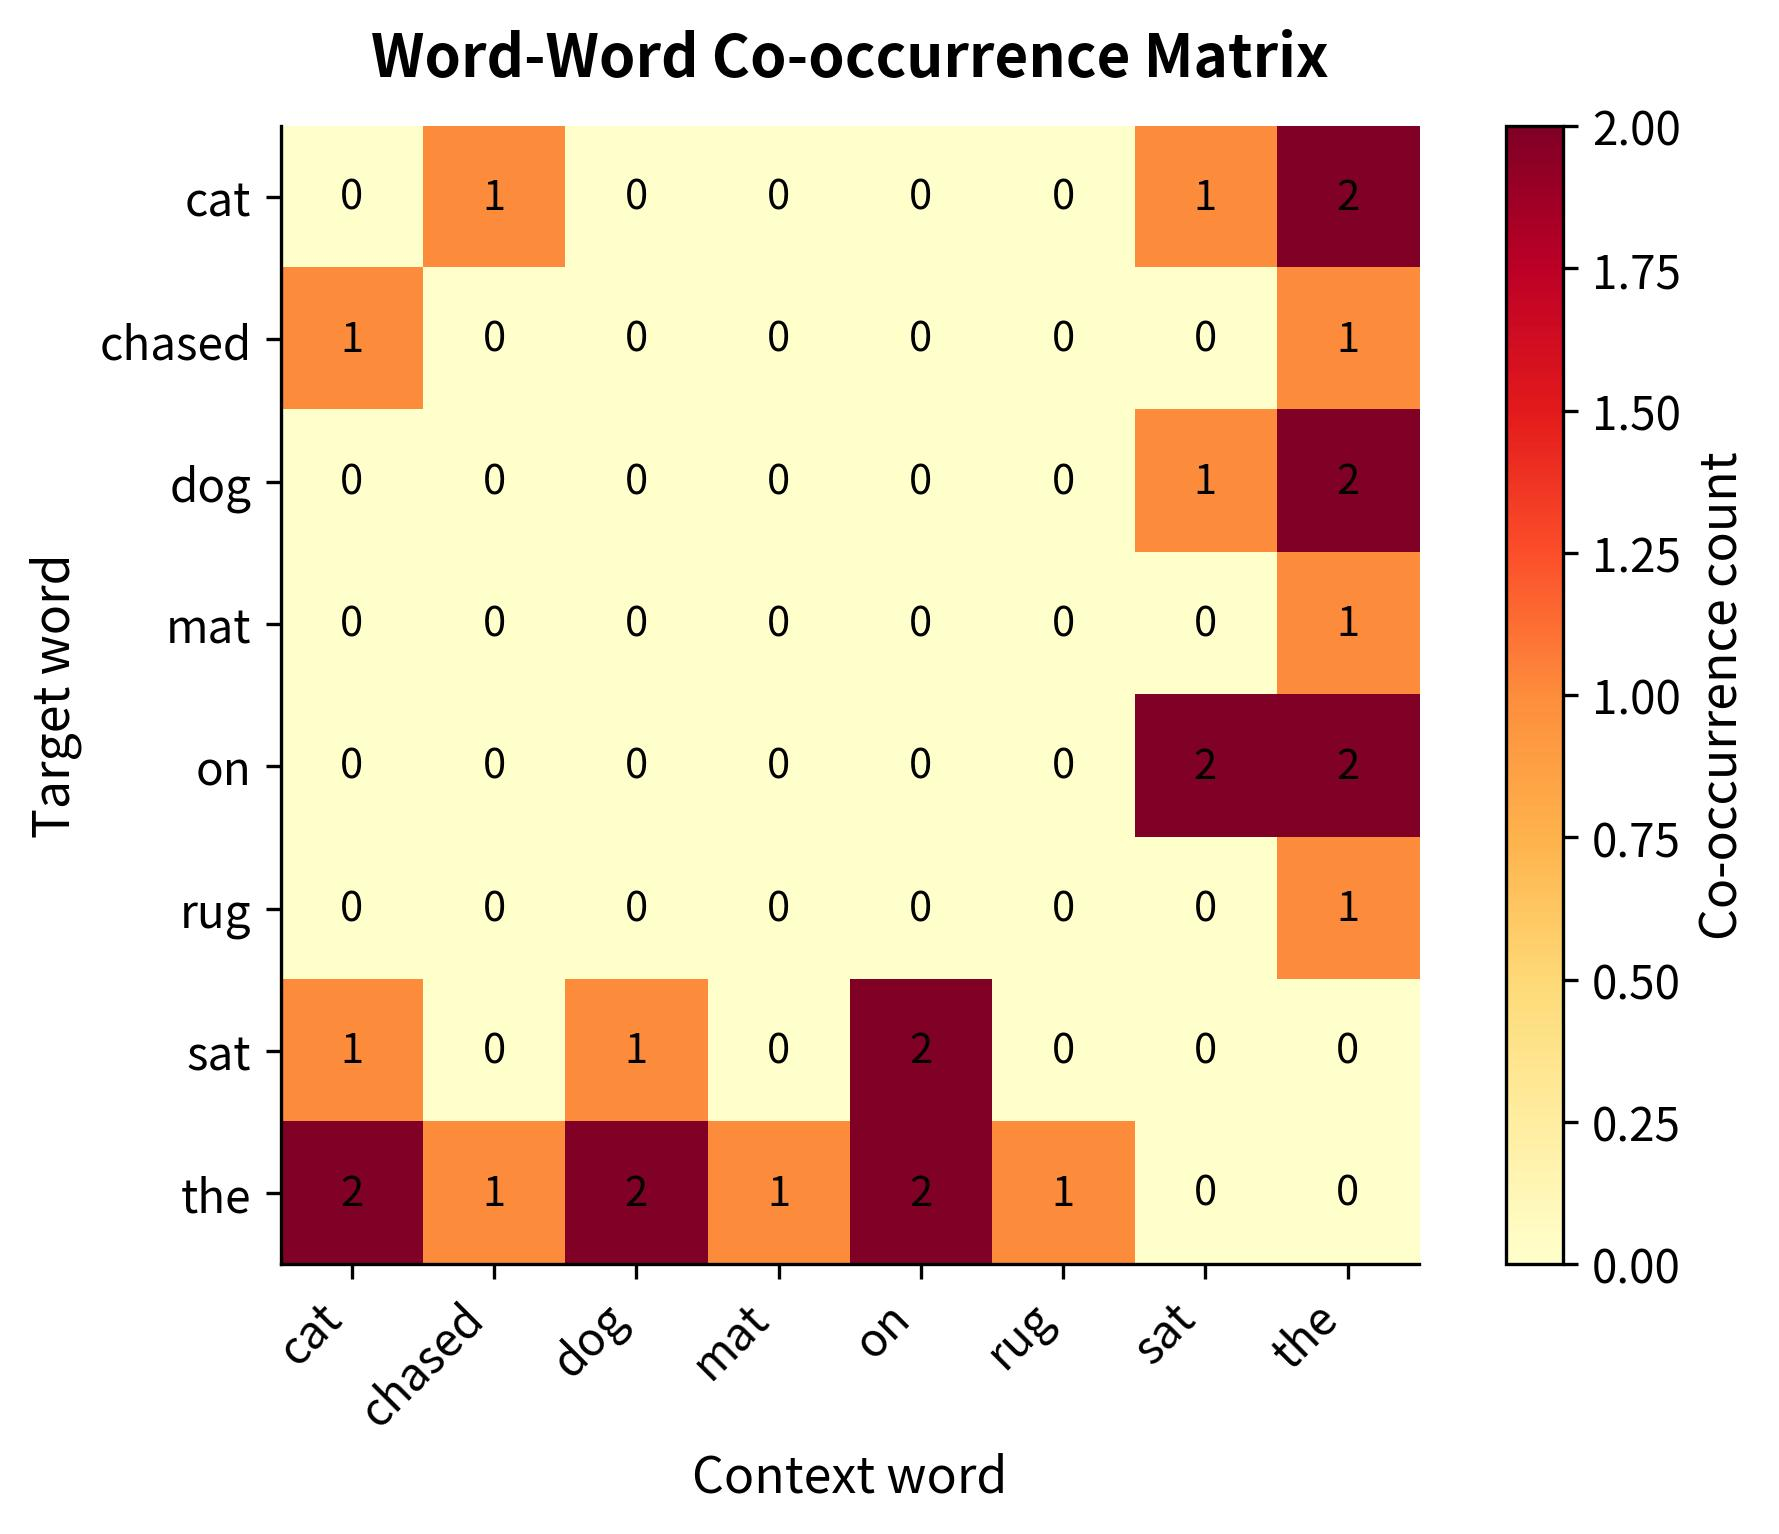


The intuition is simple: words with similar co-occurrence patterns tend to have similar representations.

## 2. Global co-occurrence statistics

A co-occurrence happens when two words appear near each other within a defined context window.

Suppose we use a context window of one word on either side.

For the sentence:

`the cat drinks milk`

When the target word is `cat`, its context words are `the` and `drinks`.

GloVe counts these relationships across the corpus, producing statistics that summarize how words occur with other words.

These counts provide information about a word's usage, not merely its frequency in isolation.

### 3. Word–context matrix

A word–context matrix stores co-occurrence counts. Rows represent target words; columns represent context words. Each cell tells us how often that pair co-occurs.

For example, imagine this tiny corpus:

- “ice is cold”
- “ice is solid”
- “steam is hot”
- “steam is gas”

A simplified matrix might look like this:

| Target word | cold | solid | hot | gas |
| ----------- | ---- | ----- | --- | --- |
| ice         | 3    | 4     | 0   | 0   |
| steam       | 0    | 0     | 4   | 3   |

Illustrative counts only; actual counts depend on the corpus and context-window definition.

Notice that `ice` is associated with `cold` and `solid`, whereas `steam` is associated with `hot` and `gas`. Those different patterns provide useful signals for learning their representations.



A real corpus may contain hundreds of thousands of vocabulary items. Its matrix is enormous and mostly zeros, so GloVe trains efficiently using the nonzero co-occurrence entries rather than processing every possible word pair.

### 4. How does GloVe learn embeddings?



GloVe learns low-dimensional vectors that capture information in the co-occurrence matrix.

Conceptually, it aims to make the dot product of a target-word vector and a context-word vector approximate the logarithm of their co-occurrence count, with bias terms:

\\[ \mathbf{w}\_i^\top\tilde{\mathbf{w}}\_j+b_i+\tilde b_j \approx \log(X\_{ij}) \\]

Where:

- \\(X\_{ij}\\): number of times context word \\(j\\) occurs near target word \\(i\\).
- \\(\mathbf{w}\_i\\): target-word embedding.
- \\(\tilde{\mathbf{w}}\_j\\): context-word embedding.
- \\(b_i,\tilde b_j\\): learned bias terms.

The logarithm helps handle the wide range of co-occurrence counts. GloVe learns these parameters by minimizing a weighted least-squares objective.


You don't need to memorize the full optimization details yet. The important idea is that the model learns vectors whose relationships reflect corpus-wide word co-occurrence patterns.

## 5. What is the difference from Word2Vec?

| Word2Vec                                         | GloVe                                                   |
| ------------------------------------------------ | ------------------------------------------------------- |
| Learns through a word-prediction objective       | Learns through a co-occurrence reconstruction objective |
| Uses context windows to create training examples | Aggregates co-occurrence counts across the corpus       |
| Learns embeddings from prediction errors         | Learns embeddings by fitting global statistics          |

Both use context to learn dense word representations. The distinction is their training objective, not that one uses context and the other doesn't. GloVe combines global count information with a learned vector-space representation.

## What you should remember 🎯

1. GloVe stands for Global Vectors for Word Representation.
2. Co-occurrence means two words appear within a defined context.
3. The word–context matrix records these relationships across a corpus.
4. GloVe learns dense embeddings from global co-occurrence statistics.
5. Its objective fits vector dot products to log co-occurrence counts, using bias terms.
6. Unlike Word2Vec's prediction objective, GloVe directly models aggregated co-occurrence statistics.

---